<a href="https://colab.research.google.com/github/psh-computer/Machine-Learning/blob/main/day03_1_STD10_pipeline_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ---------------------------------------------
# [S0-1] 패키지 설치 (버전 고정)
# ---------------------------------------------
# huggingface-hub : 모델 허브 연동
# tqdm : 진행 바 출력
!pip install -q \
  huggingface-hub==0.23.4 \
  tqdm==4.66.4

# 한글 폰트
!apt-get install -y fonts-nanum > /dev/null 2>&1
print('패키지 설치 완료')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 402.6/402.6 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.3/78.3 kB 8.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformers 5.18.0 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.23.4 which is incompatible.
dataproc-spark-connect 1.1.0 requires tqdm>=4.67, but you have tqdm 4.66.4 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.23.4 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 0.23.4 which is incompatible.
peft 0.21.1 requires huggingface-hub>=0.25.0, but you have huggingface-hub 0.23.4 which is incompatible.
tobler 0.14.0 requires tqdm>=4.67, but y

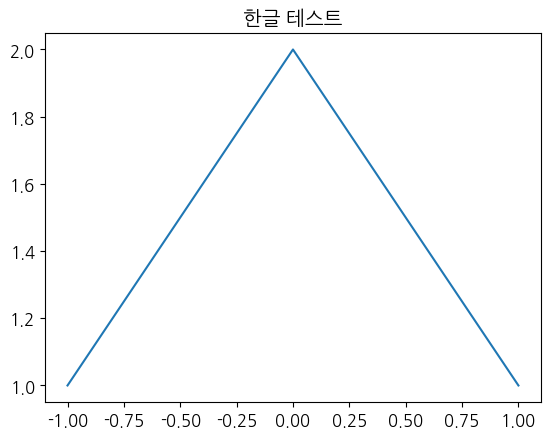

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

# 설치된 나눔길 찾기 및 캐시 업데이트
fe = fm.FontEntry(
    fname=r'/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
    name='NanumGothic'
)

fm.fontManager.ttflist.insert(0, fe)
plt.rcParams.update({'font.size': 12, 'font.family': 'NanumGothic'})

plt.title('한글 테스트')
plt.plot([-1, 0, 1], [1, 2, 1])
plt.show()

In [ ]:
# -------------------------------------------
# [S0-2] 전체 import + 버전 확인
# -------------------------------------------

import os
import random
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torchvision.models as models

from PIL import Image, ImageFilter
from tqdm import tqdm

# 버전 확인
print(f'torch         : {torch.__version__}')
print(f'torchvision   : {torchvision.__version__}')
print(f'numpy         : {np.__version__}')
print(f'PIL           : {Image.__version__}')

# GPU 확인
if torch.cuda.is_available():
  gpu_name = torch.cuda.get_device_name(0)
  gpu_mem  = torch.cuda.get_device_properties(0).total_memory / 1024**3
  print(f'GPU           : {gpu_name} ({gpu_mem:.1f} GB)')
else:
  print("GPU            : 없음 (CPU 모드)")

torch         : 2.11.0+cu130
torchvision   : 0.26.0+cu130
numpy         : 2.1.3
PIL           : 11.3.0
GPU           : Tesla T4 (14.6 GB)


In [ ]:
# ------------------------------------------
# SEED 고정 + device + 전역 상수
# ------------------------------------------

# 재현성 확보
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

# 장치 선택
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 하이퍼파라미터 상수
IMG_SIZE        = 96        # STL-10 기본 해상도 (96X96)
BATCH_SIZE      = 256       # SSL 배치 크기 (클수로 NT_Xent 성능 올라감)
NUM_WORKERS     = 2         # DataLoader 병령 프로세스 수
PROJ_DIM        = 128       # Projection Head 출력 지원
FEAT_DIM        = 512       # ResNet-18 encoder 출력 지원

# 정규화 상수 (ImageNet 기준)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGE_STD     = [0.229, 0.224, 0.225]

print(f'device        : {device}')
print(f'IMG_SIZE      : {IMG_SIZE}')
print(f'BATCH_SIZE    : {BATCH_SIZE}')
print(f'PROJ_DIM      : {PROJ_DIM}')


device        : cuda
IMG_SIZE      : 96
BATCH_SIZE    : 256
PROJ_DIM      : 128


SimCLR 평가의 표준 프로토콜

In [ ]:
# [S1-1] STL-10 다운로드 + 각 split 통계 출력
# transform=None => PIL Image로 직접 반환 (나중에 직접 적용할 예정)

DATA_ROOT = "./data"

print("STL-10 다운로드 중 (약 2.6 GB - 첫 실행 시 몇 분 소요)")
stl_unlabeled = datasets.STL10(DATA_ROOT, split='unlabeled', download=True)
stl_train = datasets.STL10(DATA_ROOT, split='train', download=True)
stl_test = datasets.STL10(DATA_ROOT, split='test', download=True)
print('다운로드 완료')

# 각 split 기본 정보 출력
print(f'{'split' : <12} {'샘플 수':>8} {'이미지 shape':>20} 레이블')
print("-"* 55)

for name, ds in [("unlabeled", stl_unlabeled), ('train', stl_train), ("test", stl_test)]:
  sample_img, label = ds[0]
  img_arr = np.array(sample_img)    # PIL => numpy: (H, W, C)
  has_label = "V" if label != -1 else "X (label=-1)"
  print(f'{name:<12} {len(ds):>8} {str(img_arr.shape):>20} {has_label}')

# 클래스 이름 확인
CLASS_NAMES = stl_train.classes
print(f'\n 클래스 ({len(CLASS_NAMES)}종): {CLASS_NAMES}')


STL-10 다운로드 중 (약 2.6 GB - 첫 실행 시 몇 분 소요)


100%|██████████| 2.64G/2.64G [05:26<00:00, 8.09MB/s]


다운로드 완료
split            샘플 수            이미지 shape 레이블
-------------------------------------------------------
unlabeled      100000          (96, 96, 3) X (label=-1)
train            5000          (96, 96, 3) V
test             8000          (96, 96, 3) V

 클래스 (10종): ['airplane', 'bird', 'car', 'cat', 'deer', 'dog', 'horse', 'monkey', 'ship', 'truck']


[시각화 1] STL-10 train - 클래스별 대표 이미지


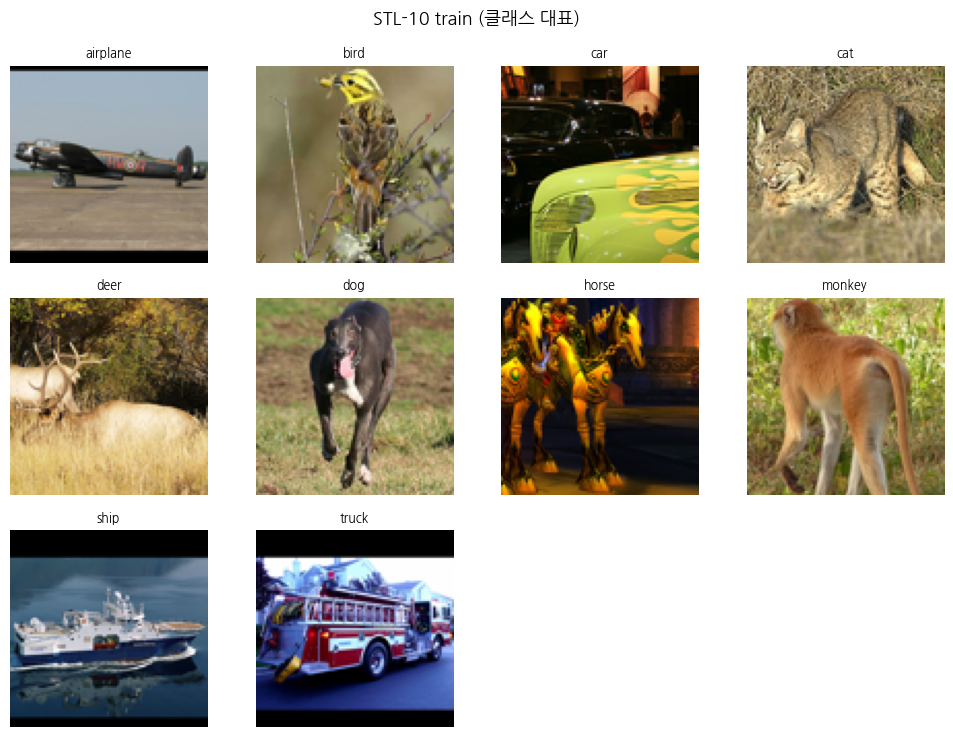

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch


# [S1-2] 시각화 1 - 이미지 그리드
def show_grid(dataset, title, n=16, use_label=True):
    """
    데이터셋에서 이미지를 선택해 그리드로 시각화한다.

    use_label=True:
        클래스별 대표 이미지 수집

    use_label=False:
        데이터셋 앞에서부터 n장 선택
    """

    ncols = 4
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(ncols * 2.5, nrows * 2.5)
    )

    # Axes를 1차원 배열로 변환
    axes = np.array(axes).reshape(-1)

    imgs = []
    labels = []

    # ---------------------------------
    # 1. 클래스별 대표 이미지 수집
    # ---------------------------------
    if use_label and hasattr(dataset, "classes"):

        collected = {}

        for img, label in dataset:
            label = int(label)

            if label not in collected:
                collected[label] = img

            # n개 클래스의 대표 이미지를 수집하면 종료
            if len(collected) == n:
                break

        indices = sorted(collected.keys())

        imgs = [collected[k] for k in indices]
        labels = indices

    # ---------------------------------
    # 2. 라벨 없이 앞에서부터 이미지 수집
    # ---------------------------------
    else:
        count = min(n, len(dataset))

        for i in range(count):
            item = dataset[i]
            img = item[0]

            imgs.append(img)
            labels.append(-1)

    # ---------------------------------
    # 3. 이미지 시각화
    # ---------------------------------
    for ax, img, label in zip(axes, imgs, labels):

        # Tensor 이미지 처리
        if isinstance(img, torch.Tensor):

            img = img.detach().cpu()

            # (C, H, W) -> (H, W, C)
            if img.ndim == 3:
                if img.shape[0] in (1, 3):
                    img = img.permute(1, 2, 0)

            img = img.numpy()

        # PIL 이미지 처리
        else:
            img = np.array(img)

        # 평균과 표준편차로 정규화된 이미지라면
        # 시각화 전에 역정규화가 필요할 수 있음
        ax.imshow(img)
        ax.axis("off")

        if (
            use_label
            and hasattr(dataset, "classes")
            and label >= 0
        ):
            ax.set_title(
                dataset.classes[label],
                fontsize=9
            )
        else:
            ax.set_title("unlabeled", fontsize=8)

    # ---------------------------------
    # 4. 남은 서브플롯 숨기기
    # ---------------------------------
    for ax in axes[len(imgs):]:
        ax.set_visible(False)

    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


# =====================================
# 실행
# =====================================

print("[시각화 1] STL-10 train - 클래스별 대표 이미지")

show_grid(
    stl_train,
    "STL-10 train (클래스 대표)",
    n=10,
    use_label=True
)